# Integrazione delle equazioni del moto (CMS 5)

Questo capitolo costruisce un codice di *molecular dynamics* completo partendo
dalle equazioni di Newton: prima la teoria (Taylor, Verlet, errori, ensemble
microcanonico), poi il codice eseguito commentato passo passo, poi la lettura
dei risultati. Il riferimento sono le slide CMS 5; dove le slide citano
risultati di altri codici (per esempio LAMMPS), il valore viene presentato
come **riferimento** e confrontato con quanto produce il nostro codice.

Sistema studiato: argento con potenziale di Lennard-Jones (stessi parametri
del CMS 4: $\sigma = 2.644$ Å, $\varepsilon = 0.345$ eV, $r_c = 4.5$ Å),
reticolo FCC perfetto con condizioni periodiche, energie in eV, distanze in Å,
tempi in s (fs e ps nei grafici).

## 1. Il problema: integrare le equazioni di Newton

Per un sistema di $N$ particelle le equazioni di Newton sono

$$
m_i \ddot{\vec r}_i = -\vec\nabla_{\vec r_i} V(\vec r_1, \dots, \vec r_N),
\qquad i = 1, \dots, N .
$$

Sono $3N$ equazioni differenziali del secondo ordine **accoppiate**: la forza
sulla particella $i$ dipende da tutte le altre attraverso il potenziale
$V$. Non esiste soluzione analitica generale: non si cerca di integrare a
mano, si usa un **metodo alle differenze finite**.

L'idea è la seguente. Il tempo viene discretizzato in passi $\Delta t$; sia
$\{(x, v)\}_t$ la configurazione (posizioni e velocità) al tempo $t$. Un
*algoritmo di integrazione* è una regola che, data la configurazione a
$t$, produce la configurazione a $t + \Delta t$:

$$
\{(x, v)\}_t \;\xrightarrow{\ \Delta t \ }\; \{(x, v)\}_{t+\Delta t}
\;\xrightarrow{\ \Delta t \ }\; \{(x, v)\}_{t+2\Delta t} \;\to\; \dots
$$

Tutta la qualità del metodo dipende da quanto è buona questa regola: gli
errori si accumulano passo dopo passo, quindi a ogni passo devono essere
piccoli.


## 2. Idea di base e sviluppo di Taylor

La mossa naturale è lo sviluppo di Taylor della posizione attorno al tempo
$t$. Con $v$, $a$, $b$ derivate rispetto al tempo:

$$
x(t+\Delta t) = x(t) + v(t)\,\Delta t + \tfrac{1}{2}a(t)\,\Delta t^2
+ \tfrac{1}{6}b(t)\,\Delta t^3 + \dots
$$

Se conosco $x, v, a, b$ al tempo $t$ posso calcolare $x(t+\Delta t)$ e, con
gli sviluppi analoghi, anche le derivate nei tempi successivi: in linea di
principio **genero l'evoluzione completa** del sistema. Il limite dello
sviluppo è il suo errore di troncamento: voglio errori piccoli anche per
passi $\Delta t$ "lunghi", così che la dinamica resti affidabile.

Restano due domande aperte, che guidano la costruzione degli algoritmi:

1. **Dove sono le equazioni di Newton** (cioè il potenziale atomistico) in
   questo schema? Lo sviluppo di Taylor è pura cinematica: di fisica c'è
   solo $a = f/m$, e la forza va calcolata **ogni passo** dal potenziale.
2. **Quanto è grave** il vincolo che la derivata temporale di $a$ sia
   costante ($\dot b = 0$)? Implica che l'accelerazione varia linearmente
   nel tempo: valido per pochi passi, ma la costanza di $b$ è un'ipotesi
   restrittiva se la mantengo per troppo tempo.

## 3. Errori di troncamento e scelta del time step

La qualità di un algoritmo si misura con un **test standard**: un sistema
isolato deve conservare l'energia totale $E = K + V$. Regola empirica del
corso:

$$
\frac{dE}{E} < 10^{-5}.
$$

Due vincoli sulla scelta di $\Delta t$:

- $\Delta t$ deve essere **molto più piccolo** dei tempi caratteristici dei
  processi fondamentali. Dalla curvatura del potenziale LJ al suo minimo
  (cella 9.1) si stima un periodo di vibrazione di reticolo di **0.353 ps**:
  quindi $\Delta t \ll 0.353$ ps.
- In pratica il vincolo sulla conservazione dell'energia è **più stringente**
  di quello sui periodi: il range utile è $\Delta t \sim 1\text{–}10$ fs.

Attenzione: a temperature più alte gli atomi si muovono di più, le vibrazioni
sono più ampie e il potenziale più anarmonico; può servire un $\Delta t$ più
piccolo. Il capitolo verificherà numericamente entrambi gli effetti
(sezione 11).


## 4. Schema "di ordine superiore" (solo teoria)

Per avere un'idea di cosa cerca uno schema migliore, estendo lo sviluppo fino
a $\Delta t^4$ usando $x, v, a, b$ e ponendo $\dot b = 0$:

$$
\begin{aligned}
x(t+\Delta t) &= x + v\,\Delta t + \tfrac{1}{2}a\,\Delta t^2
                 + \tfrac{1}{6}b\,\Delta t^3 \\[2pt]
v(t+\Delta t) &= v + a\,\Delta t + \tfrac{1}{2}b\,\Delta t^2 \\[2pt]
a(t+\Delta t) &= a + b\,\Delta t \\[2pt]
b(t+\Delta t) &= b
\end{aligned}
$$

Ottenengo un sistema di quattro equazioni accoppiate in cui, nota la
configurazione $(x, v, a, b)$ a $t$, calcolo $(x, v, a, b)$ a $t+\Delta t$.
È un passaggio **concettuale**, non un algoritmo da usare: mostra che
servono quattro "livelli" di derivate e che tenere $b$ costante è il punto
debole. La conclusione è che serve un modo più efficiente di usare le
derivate note — che è esattamente ciò che fa Verlet.

## 5. L'algoritmo di Verlet

### 5.1 Verlet standard

L'idea di Verlet è espandere $x(t+\Delta t)$ **e** $x(t-\Delta t)$ al terzo
ordine e **sommarle**. I termini dispari si cancellano:

$$
x(t+\Delta t) + x(t-\Delta t) = 2x(t) + a(t)\,\Delta t^2
+ \mathrm{err}(\Delta t^4).
$$

Con $a = f/m$ (per ciascuna componente: sono $3N$ equazioni), riordino:

$$
\vec r_i(t+\Delta t) = 2\vec r_i(t) - \vec r_i(t-\Delta t)
+ \frac{\vec f_i(t)}{m_i}\,\Delta t^2 + \mathrm{error}(\Delta t^4).
$$

Proprietà:

- schema **semplice**: a ogni passo serve una sola valutazione delle forze;
- **conserva molto bene l'energia** anche con passi "grandi";
- è **reversibile nel tempo**: invertendo il tempo (e le velocità) si
  ripercorre la traiettoria. Questa è una proprietà di simmetria molto
  rara e utile come test.

Svantaggi: servono **tre tempi diversi** ($t-\Delta t$, $t$, $t+\Delta t$)
e le velocità si conoscono solo indirettamente, come differenza finita
centrata tra le posizioni "future" e "passate":

$$
\vec v(t) = \frac{\vec r(t+\Delta t) - \vec r(t-\Delta t)}{2\Delta t}
+ \mathrm{error}(\Delta t^2).
$$

### 5.2 Velocity Verlet (quello usato nel corso)

Algoritmo equivalente — produce **le stesse traiettorie** — ma che tratta le
velocità in modo diretto:

$$
\begin{aligned}
x(t+\Delta t) &= x(t) + v(t)\,\Delta t
                 + \tfrac{1}{2}a(t)\,\Delta t^2 + \mathrm{err}(\Delta t^4) \\[2pt]
v(t+\Delta t) &= v(t) + \frac{a(t) + a(t+\Delta t)}{2}\,\Delta t
                 + \mathrm{err}(\Delta t^3).
\end{aligned}
$$

Il ciclo di un passo è il seguente:

1. Conosco $x(t)$, $v(t)$ e quindi $a(t) = f(t)/m$ (dalla funzione forze).
2. Con la prima equazione calcolo $x(t+\Delta t)$.
3. Con la funzione forze **sulle nuove posizioni** calcolo $a(t+\Delta t)$.
4. Con la seconda equazione calcolo $v(t+\Delta t)$.
5. Ripeto dal passo 1.

C'è un apparente paradosso: il passo richiede $a(t)$ **e** $a(t+\Delta t)$,
ma $a(t+\Delta t)$ nasce da $x(t+\Delta t)$. Non c'è ambiguità nell'ordine:
prima si aggiornano le posizioni con $a(t)$, poi si valutano le forze sulle
posizioni nuove, poi si aggiornano le velocità con la media delle due
accelerazioni.

> **Nota sul codice.** Gli indici $(i)$ delle particelle non hanno nulla a
> che fare con il tempo: $i = 1 \dots N$ è l'atomo, non il passo. Non si
> salvano posizioni e velocità a tutti i tempi (servirebbero $O(N \times
> N_{steps})$ dati): i vettori `pos`, `vel`, `force` vengono **sovrascritti**
> a ogni passo, tenendo solo le osservabili che ci interessano.

## 6. Unità di misura

Il codice lavora in **unità di codice**: le unità sono scelte in modo che i
numeri restino $O(1)$. Energia in eV, lunghezze in Å, tempi in s (fs = $10^{-15}$ s,
ps = $10^{-12}$ s). Qual è l'unità di massa coerente? Da $E = mc^2$:

$$
[m] = \frac{\text{eV}\cdot\text{s}^2}{\text{Å}^2}.
$$

Conversione in kg: $1\,\text{eV} = 1.6\times10^{-19}$ J e
$1\,\text{Å}^2 = 10^{-20}\ \text{m}^2$, quindi

$$
1\,\frac{\text{eV}\cdot\text{s}^2}{\text{Å}^2}
= \frac{1.6\times10^{-19}\ \text{J}\cdot\text{s}^2}{10^{-20}\ \text{m}^2}
= 16\ \text{kg}.
$$

Per l'argento ($^{108}$Ag): 108 g di argento contengono una mole,
$6.023\times10^{23}$ atomi, quindi la massa di un atomo è
$108\times1.66\times10^{-27}$ kg (il fattore $1.66\times10^{-27}$ kg è
$1/6.023\times10^{23}$ di grammo). In unità di codice:

$$
m = \frac{108 \times 1.66\times10^{-27}}{16}.
$$

La costante di Boltzmann in queste unità è $k_B = 8.618461\times10^{-5}$ eV/K
(= $1/11603$ eV/K, valore stampato nella cella di setup). Ne seguono due
numeri utili, stampati anch'essi: a temperatura ambiente ($300$ K) l'energia
termica è $k_B T = 0.0259$ eV, cioè circa $1/40$ eV; e viceversa
$1/40$ eV corrisponde a $T \approx 290$ K.


In [ ]:
import sys
from pathlib import Path
from time import perf_counter


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    src_path = str(root / "src")
    if src_path not in sys.path:
        sys.path.insert(0, src_path)
    return root


PROJECT_ROOT = _setup_path()

import matplotlib.pyplot as plt
import numpy as np

from computational_course.fcc_lattice import fcc_supercell
from computational_course.lennard_jones import (
    build_neighbor_list,
    lennard_jones_energy,
    lennard_jones_forces,
    lennard_jones_pair,
)
from computational_course.md import (
    DEFAULT_SEED,
    analizza_traiettoria,
    assign_vel,
    instantaneous_T,
    kinetic_energy,
    radial_distribution,
    run_md,
)

GEN = PROJECT_ROOT / "notebooks" / "05_molecular_dynamics" / "generated"
GEN.mkdir(parents=True, exist_ok=True)

SIGMA = 2.644  # Å
EPSILON = 0.345  # eV
RC = 4.5  # Å, cutoff
RPRIME = 4.0  # Å, inizio della coda polinomiale liscia (CMS 4)
KB = 1.0 / 11603.0  # eV/K
MASS = 108.0 * 1.66e-27 / 16.0  # massa di Ag in unità di codice (1 unità = 16 kg)
FS = 1e-15  # un femtosecondo in secondi

# verifica della conversione 1 eV*s^2/A^2 = 16 kg
assert abs((1.6e-19 * 1.0**2 / 1e-20) - 16.0) < 1e-12

print(f"dati generati in: {GEN.relative_to(PROJECT_ROOT)}")
print("figure salvate in: figures/")
print(f"massa Ag  = {MASS:.4e} kg*16 = {MASS * 16:.4e} kg")
print(f"kB        = {KB:.6e} eV/K (= 1/11603)")
print(f"kB * 300 K = {KB * 300:.4f} eV  (~ 1/40 eV)")
print(
    f"parametri LJ: sigma = {SIGMA} Å, epsilon = {EPSILON} eV, r_c = {RC} Å, r' = {RPRIME} Å"
)
print(f"T corrispondente a 1/40 eV = {(1.0 / 40.0) / KB:.0f} K")
print(f"seed fisso delle velocita' iniziali = {DEFAULT_SEED}")


Project root: /Users/francesco/dev/computational-course
massa Ag  = 1.1205e-26 kg*16 = 1.7928e-25 kg
kB        = 8.618461e-05 eV/K (= 1/11603)
kB * 300 K = 0.0259 eV  (~ 1/40 eV)
parametri LJ: sigma = 2.644 Å, epsilon = 0.345 eV, r_c = 4.5 Å, r' = 4.0 Å
T corrispondente a 1/40 eV = 290 K
seed fisso delle velocita' iniziali = 33282739


## 7. Ensemble microcanonico (NVE) e temperatura istantanea

Il nostro sistema è **isolato**: non scambia energia con l'esterno, quindi
viviamo nell'ensemble **microcanonico** (NVE) e l'energia totale

$$
E = K + V = \text{costante}
$$

(a meno dell'errore di troncamento dell'algoritmo, che è artefatto e si
riduce con $\Delta t$).

Nel microcanonico la temperatura **non è un parametro imposto**: è una
grandezza *definita* attraverso l'energia cinetica istantanea, sfruttando il
teorema di equipartizione. Con

$$
K(t) = \frac{1}{2}\sum_i m_i |\vec v_i(t)|^2
\qquad\text{e}\qquad
K(t) \equiv \frac{N_{dof}\,k_B\,T(t)}{2},
\qquad N_{dof}\approx 3N,
$$

si definisce

$$
\boxed{\,T(t) = \frac{2K(t)}{N_{dof}\,k_B}\,}
$$

Punti da tenere a mente:

- $T(t)$ **fluttua** nel tempo: non è costante come nell'ensemble canonico.
  Le fluttuazioni della temperatura cinetica scalano come $1/\sqrt{N}$, come
  quelle dell'energia cinetica. Le slide, in un punto, scrivono $1/N$:
  il coefficiente corretto è $1/\sqrt{N}$ e la sezione 12 lo **verifica
  numericamente** variando $N$.
- Sulla media temporale lunga si recupera il teorema di equipartizione,
  tipico del comportamento canonico: la media di $T(t)$ coincide con la
  temperatura dell'ensemble.
- Con il momento totale azzerato i gradi di libertà effettivi sono $3N-3$.
  Per coerenza con le slide qui si usa $N_{dof} = 3N$; per $N$ grande la
  differenza è trascurabile ($3/3N$), ma va **segnalata**.

> Due fluttuazioni diverse, da non confondere:
>
> - le fluttuazioni di $E$ sono **artificiali** (dovute al troncamento): si
>   riducono diminuendo $\Delta t$;
> - le fluttuazioni di $T$ sono **fisiche**: non si riducono con $\Delta t$;
>   per diminuirle serve un sistema più grande (numero di particelle $N$
>   maggiore).

## 8. Condizioni iniziali e assegnazione delle velocità

### 8.1 Posizioni iniziali

Con condizioni periodiche in tutte e tre le direzioni, il **reticolo
perfetto** è una configurazione di forze nulle: corrisponde a un minimo
$U_0$ dell'energia potenziale. Le velocità iniziali portano un'energia
cinetica $K_0 = \tfrac{3}{2}N k_B T_0$, quindi $E_0 = U_0 + K_0$.

Se $T_0$ è sufficientemente bassa il sistema resta vicino al minimo e il
potenziale si può trattare in **approssimazione armonica**: gli atomi
oscillano attorno alle posizioni di equilibrio e l'energia cinetica iniziale
si ripartisce con l'energia potenziale, con la conseguenza

$$
T_f \cong \tfrac{1}{2} T_i .
$$

Quindi, per simulare a $T = 100$ K si assegnano velocità corrispondenti a
$T_i = 200$ K. Ma $T_i$ **non ha significato fisico**: è solo il valore di
partenza; l'unica grandezza significativa è $T_f$, quella misurata dopo
l'equilibrazione. Se le posizioni non sono al minimo (per esempio senza PBC)
o se si va oltre il regime armonico, $T_i$ va **tarato** sui risultati della
simulazione: l'esercizio 2 misura $T_f/T_i = 0.503$ per $T_i = 1200$ K
(regola armonica, errore dello 0.65%), mentre a temperature più alte
l'anarmonicità allinea $T_f$ leggermente sopra $T_i/2$.

### 8.2 Distribuzione di Boltzmann

All'equilibrio (ensemble canonico, o microcanonico nel limite
termodinamico) le velocità seguono la distribuzione di Maxwell-Boltzmann:

$$
f(v_x)\,dv_x = \frac{1}{\sqrt{2\pi}}\sqrt{\frac{m}{k_BT}}\,
e^{-\frac{m v_x^2}{2k_BT}}\,dv_x .
$$

Potremmo assegnare direttamente questa distribuzione, ma il codice parte da
una distribuzione **più semplice — uniforme in $[-C, C]$** — e l'obiettivo
didattico è **verificare** che il sistema, evolvendo con le forze, si
equilibri verso la distribuzione di Boltzmann (sezione 10).

### 8.3 Come si assegnano le velocità

Per ogni componente di ogni atomo si estrae un numero casuale uniforme in
$[-C, C]$ con

$$
C = \sqrt{\frac{3 k_B T}{m}},
$$

che garantisce l'**energia cinetica media corretta** (la varianza della
distribuzione uniforme è $C^2/3 = k_BT/m$, esattamente il valore di
equipartizione per componente). Poi due correzioni, **in quest'ordine**:

1. **Azzerare il momento totale.** La media finita di estrazioni casuali non
   dà $\langle v \rangle = 0$: il centro di massa avrebbe una velocità
   residua. Le equazioni di Newton conservano il momento, quindi quella
   deriva resterebbe **per sempre** e l'intera cella traslerebbe durante
   l'evoluzione (esercizio 1).
2. **Riscala la temperatura** a $T$ desiderata: si calcola la $T'$ della
   distribuzione estratta e si moltiplicano tutte le velocità per
   $\sqrt{T/T'}$.

L'ordine conta: la rimozione del momento cambia la $T'$ (toglie energia
cinetica), quindi se si riscala prima e poi si azzera il momento la
temperatura finale non è più quella richiesta. Il **seme casuale è fisso**
(`33282739`) per rendere la simulazione riproducibile.


## 9. Implementazione: inizializzazione e ciclo temporale

### 9.1 Setup del sistema

Reticolo FCC perfetto al passo di minimizzazione LJ $a_0 = 2^{1/6}\sigma
\sqrt{2}$ (distanza primo vicino = minimo del potenziale), con condizioni
periodiche. Il box è $4\times4\times4$ celle = **256 atomi**, lato
$L = 4a_0 = 16.8$ Å (ricordarsi il vincolo $r_c < L/2$ della minima
immagine, che con 256 atomi è ben rispettato).

In [ ]:
A_LJ = 2.0 ** (1.0 / 6.0) * SIGMA * np.sqrt(2.0)
NCELLS = 4
pos, cell = fcc_supercell(A_LJ, NCELLS, NCELLS, NCELLS)
BOX = np.diag(cell)
NATOMS = pos.shape[0]

nnbrs, whichnbr = build_neighbor_list(pos, RC, box=BOX)
epot0 = lennard_jones_energy(
    pos, SIGMA, EPSILON, nnbrs, whichnbr, box=BOX, rprime=RPRIME, rc=RC
)
force0 = lennard_jones_forces(
    pos, SIGMA, EPSILON, nnbrs, whichnbr, box=BOX, rprime=RPRIME, rc=RC
)

# --- grandezze strutturali, usate nel testo ---
D_NN = A_LJ / np.sqrt(2.0)  # distanza primo vicino FCC
L_BOX = float(BOX[0])  # lato del box
R_MAX = L_BOX / 2.0  # limite di minima immagine

# periodo di vibrazione del reticolo: omega = sqrt(V''(d_nn)/m) con V'' = 72 eps/sigma^2
K_LJ = 72.0 * EPSILON / SIGMA**2  # eV/Å^2
OMEGA = np.sqrt(K_LJ / MASS)  # rad/s
T_VIB = 2.0 * np.pi / OMEGA  # s

# salto del potenziale al cutoff, con e senza raccordo polinomiale
r_probe = RC - 1e-6
two = np.array([[0.0, 0.0, 0.0], [r_probe, 0.0, 0.0]])
nb2, wn2 = build_neighbor_list(two, RC)
v_sharp = lennard_jones_pair(r_probe, SIGMA, EPSILON)
v_smooth = lennard_jones_energy(two, SIGMA, EPSILON, nb2, wn2, rprime=RPRIME, rc=RC)

print(f"a0 = {A_LJ:.4f} Å, box = {BOX} Å, N = {NATOMS}")
print(f"distanza primo vicino d_nn = a0/sqrt(2) = {D_NN:.4f} Å")
print(f"lato del box L = {L_BOX:.3f} Å, limite minima immagine L/2 = {R_MAX:.3f} Å")
print(f"periodo vibrazione reticolo (da V'' al minimo) = {T_VIB * 1e12:.3f} ps")
print(f"lato minimo del box (r_c < L/2): 3 a0 = {3 * A_LJ:.3f} Å")
print(
    f"potenziale a r = rc: sharp {v_sharp * 1e3:.3f} meV, con raccordo {v_smooth * 1e3:.3e} meV"
)
print(f"coordinazione media = {nnbrs.mean():.1f} (atteso 18: 12+6 vicini entro {RC} Å)")
print(f"Epot(0) = {epot0:.4f} eV = {epot0 / NATOMS:.4f} eV/atomo")
print(f"fmax(0) = {np.abs(force0).max():.2e} eV/Å (reticolo perfetto -> forze nulle)")


a0 = 4.1971 Å, box = [16.78835353 16.78835353 16.78835353] Å, N = 256
distanza primo vicino d_nn = a0/sqrt(2) = 2.9678 Å
lato del box L = 16.788 Å, limite minima immagine L/2 = 8.394 Å
periodo vibrazione reticolo (da V'' al minimo) = 0.353 ps
lato minimo del box (r_c < L/2): 3 a0 = 12.591 Å
potenziale a r = rc: sharp -54.441 meV, con raccordo -9.948e-10 meV
coordinazione media = 18.0 (atteso 18: 12+6 vicini entro 4.5 Å)
Epot(0) = -575.1111 eV = -2.2465 eV/atomo
fmax(0) = 1.73e-14 eV/Å (reticolo perfetto -> forze nulle)


Il reticolo perfetto ha forze nulle (a meno di errore di arrotondamento) ed
energia negativa: è la condizione di partenza ideale, perché le uniche
forze in gioco all'inizio sono quelle dovute alle velocità assegnate.

Le funzioni sono quelle del CMS 4 (`build_neighbor_list`,
`lennard_jones_energy`, `lennard_jones_forces`), estese con due argomenti
opzionali: `box` per le condizioni periodiche (minima immagine) e
`rprime`/`rc` per il raccordo polinomiale del potenziale. Il raccordo è
necessario in dinamica: con il cutoff *sharp* il potenziale salterebbe di
**-54.441 meV** ogni volta che una coppia attraversa $r_c$ (valore stampato
nella cella precedente), e questi salti rompono il criterio $dE/E < 10^{-5}$.
Con il raccordo polinomiale lo stesso salto è **-9.948e-10 meV**, cioè zero
a meno dell'errore di arrotondamento.

### 9.2 Il ciclo temporale (replica commentata delle slide)

Il codice delle slide usa le funzioni `calc_nbrs`, `calc_force`, `calc_epot`
con firma $(N, pos, r_c, s_x, s_y, s_z)$; nel progetto le stesse funzioni
hanno la firma del CMS 4 con `box` opzionale. Il ciclo è il velocity Verlet
della sezione 5.2, con **un passaggio in più rispetto alle slide**:
`force = forcenew.copy()` alla fine di ogni passo — senza di esso le forze
resterebbero quelle del passo zero e l'algoritmo sarebbe sbagliato.


In [3]:
# --- inizializzazione (t = 0) ---
pos_demo = pos.copy()
vel_demo = assign_vel(NATOMS, MASS, 2.0 * 600.0)  # Ti = 1200 K -> Tf ~ 600 K
dt_demo = 4 * FS
nMD = 200

nnbrs, whichnbr = build_neighbor_list(pos_demo, RC, box=BOX)
force = lennard_jones_forces(
    pos_demo, SIGMA, EPSILON, nnbrs, whichnbr, box=BOX, rprime=RPRIME, rc=RC
)

# --- ciclo temporale ---
for iMD in range(nMD):
    time = (iMD + 1) * dt_demo

    # (1) posizioni a t+dt usando v(t) e a(t)
    for i in range(NATOMS):
        for j in range(3):
            pos_demo[i, j] = (
                pos_demo[i, j]
                + vel_demo[i, j] * dt_demo
                + 0.5 * (force[i, j] / MASS) * dt_demo * dt_demo
            )

    # (2) forze a t+dt sulle nuove posizioni (le liste di vicini possono cambiare)
    nnbrs, whichnbr = build_neighbor_list(pos_demo, RC, box=BOX)
    epot = lennard_jones_energy(
        pos_demo, SIGMA, EPSILON, nnbrs, whichnbr, box=BOX, rprime=RPRIME, rc=RC
    )
    forcenew = lennard_jones_forces(
        pos_demo, SIGMA, EPSILON, nnbrs, whichnbr, box=BOX, rprime=RPRIME, rc=RC
    )

    # (3) velocità a t+dt con la media di a(t) e a(t+dt)
    for i in range(NATOMS):
        for j in range(3):
            vel_demo[i, j] = (
                vel_demo[i, j] + (0.5 / MASS) * (force[i, j] + forcenew[i, j]) * dt_demo
            )

    # (4) il passo successivo parte dalle forze appena calcolate
    force = forcenew.copy()  # <-- NON presente nelle slide, va aggiunto

    # (5) output: step, tempo, T istantanea, energia totale
    if (iMD + 1) % 50 == 0:
        k = kinetic_energy(vel_demo, MASS)
        print(
            f"step {iMD + 1:4d}  t = {time * 1e12:5.2f} ps  "
            f"T = {instantaneous_T(k, NATOMS):7.1f} K  E = {k + epot:10.4f} eV"
        )


step   50  t =  0.20 ps  T =   613.9 K  E =  -535.3265 eV


step  100  t =  0.40 ps  T =   613.7 K  E =  -535.3165 eV


step  150  t =  0.60 ps  T =   549.9 K  E =  -535.3129 eV


step  200  t =  0.80 ps  T =   622.7 K  E =  -535.3158 eV


Punti delicati, uno per riga del ciclo:

- **Perché due valutazioni di forza.** Il passo usa $a(t)$ *e*
  $a(t+\Delta t)$. Si aggiornano prima le posizioni con $a(t)$, poi si
  calcolano le forze nuove: l'ordine è unico, non c'è circolarità.
- **Perché ricalcolare le liste di vicini a ogni passo.** Le posizioni sono
  cambiate: qualche coppia può entrare o uscire dal cutoff. Costo $O(N^2)$
  con questa implementazione diretta; in codici di produzione si usano le
  *cell lists* e si ricostruiscono solo quando serve.
- **Perché `force = forcenew.copy()`.** Senza questa riga (mancante nelle
  slide) al passo successivo si userebbero ancora le forze del passo 0: il
  moto divergerebbe subito. Il `.copy()` garantisce che `force` e
  `forcenew` non puntino allo stesso array, che verrebbe sovrascritto.
- **Le posizioni si sovrascrivono**: `pos_demo` e `vel_demo` contengono solo
  la configurazione corrente; le osservabili (T, E) si salvano in liste
  separate.

### 9.3 Il ciclo impacchettato: `run_md`

Lo stesso ciclo, parametrizzato e con la scrittura su file, è nella funzione
`run_md` del package `computational_course` (`src/computational_course/md.py`):
accetta posizioni, velocità, massa, parametri del potenziale, box, $\Delta t$
e numero di passi; scrive un CSV passo-passo (per separare **simulazione** e
**analisi**, sezione 12) e campiona le posizioni ogni `sample_every` passi
(per la $g(r)$, sezione 13).

In [4]:
T_TARGET = 600.0
CSV_MAIN = GEN / "md_600K.csv"

vel0 = assign_vel(NATOMS, MASS, 2.0 * T_TARGET)  # Ti = 2 * Tf (regola armonica)
print(
    f"Ti assegnata = {2.0 * T_TARGET:.0f} K, "
    f"T istantanea iniziale = {instantaneous_T(kinetic_energy(vel0, MASS), NATOMS):.1f} K"
)

t_start = perf_counter()
main = run_md(
    pos,
    vel0,
    MASS,
    sigma=SIGMA,
    epsilon=EPSILON,
    rc=RC,
    box=BOX,
    rprime=RPRIME,
    dt=4 * FS,
    nsteps=3000,
    sample_every=15,
    out_file=CSV_MAIN,
)
elapsed = perf_counter() - t_start
print(
    f"3000 passi a 4 fs = 12 ps in {elapsed:.1f} s "
    f"({1000 * elapsed / 3000:.2f} ms/passo)"
)


Ti assegnata = 1200 K, T istantanea iniziale = 1200.0 K


3000 passi a 4 fs = 12 ps in 8.6 s (2.88 ms/passo)


### 9.4 Energia e temperatura nel tempo

L'energia cinetica e la temperatura istantanea sono le due osservabili che
il ciclo temporale calcola a ogni passo: la prima è un'estensione di $K$ e
$U$, la seconda è definita da $T(t) = 2K(t)/(3Nk_B)$.


K finale    = 19.5196 eV
T finale    = 589.8 K
<T> sulla finestra di produzione = 604.5 K
minimo del transitorio: T = 226.5 K a t = 0.044 ps
ultimo passo fuori dalla banda +/-20%: t = 0.060 ps; rientro in banda a t = 0.064 ps


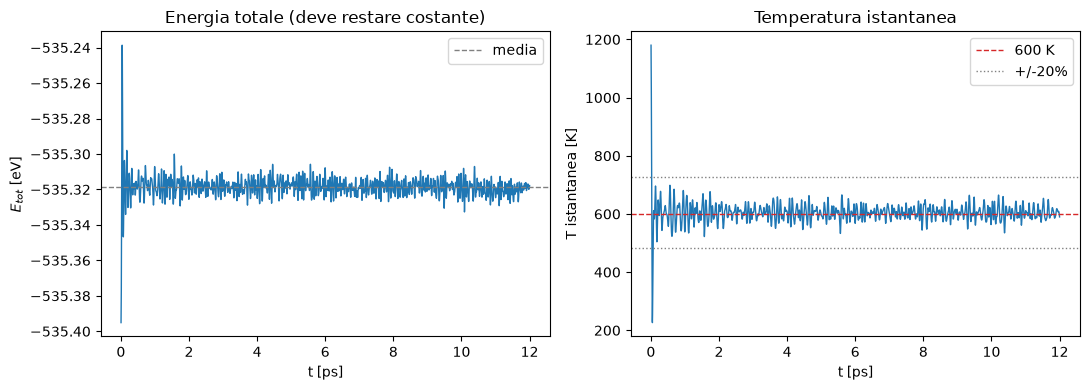

In [5]:
k_check = kinetic_energy(main["vel"], MASS)
print(f"K finale    = {k_check:.4f} eV")
print(f"T finale    = {instantaneous_T(k_check, NATOMS):.1f} K")

# --- caratterizzazione del transitorio (sezione 10) ---
T_MEAN_PROD = main["T"][500:].mean()
BAND = 0.20  # banda +/-20% attorno alla media di produzione
out_idx = np.where(np.abs(main["T"] - T_MEAN_PROD) > BAND * T_MEAN_PROD)[0]
i_min = int(np.argmin(main["T"]))
t_out_last = main["time_ps"][out_idx[-1]] if out_idx.size else 0.0
t_in = main["time_ps"][out_idx[-1] + 1] if out_idx.size < main["T"].size else 0.0
print(f"<T> sulla finestra di produzione = {T_MEAN_PROD:.1f} K")
print(
    f"minimo del transitorio: T = {main['T'][i_min]:.1f} K "
    f"a t = {main['time_ps'][i_min]:.3f} ps"
)
print(
    f"ultimo passo fuori dalla banda +/-{BAND * 100:.0f}%: t = {t_out_last:.3f} ps; "
    f"rientro in banda a t = {t_in:.3f} ps"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(main["time_ps"], main["etot"], lw=1)
axes[0].axhline(main["etot"].mean(), color="0.5", ls="--", lw=1, label="media")
axes[0].set_xlabel("t [ps]")
axes[0].set_ylabel(r"$E_{tot}$ [eV]")
axes[0].set_title("Energia totale (deve restare costante)")
axes[0].legend()

axes[1].plot(main["time_ps"], main["T"], lw=1)
axes[1].axhline(T_TARGET, color="C3", ls="--", lw=1, label=f"{T_TARGET:.0f} K")
axes[1].axhline(
    BAND * T_MEAN_PROD + T_MEAN_PROD,
    color="0.5",
    ls=":",
    lw=1,
    label=f"+/-{BAND * 100:.0f}%",
)
axes[1].axhline(T_MEAN_PROD - BAND * T_MEAN_PROD, color="0.5", ls=":", lw=1)
axes[1].set_xlabel("t [ps]")
axes[1].set_ylabel("T istantanea [K]")
axes[1].set_title("Temperatura istantanea")
axes[1].legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_E_T_600K.png", dpi=150)
plt.show()


A sinistra l'energia totale: le oscillazioni visibili sono l'**errore di
troncamento**, non fisica — la loro ampiezza dipende da $\Delta t$ (la
sezione 11 le quantifica). A destra la temperatura: parte da $T_i = 1200$ K,
scende fino a un minimo di **226.5 K** a $t = 0.044$ ps (è il momento in cui
l'energia cinetica si scarica tutta sul potenziale) e rientra nella banda
±20% attorno alla media a $t = 0.064$ ps; da lì oscilla attorno a
604.5 K.


## 10. Equilibrazione (termalizzazione)

In un sistema isolato l'energia totale si conserva, ma gli atomi si
**scambiano** energia cinetica e potenziale (e tra loro) fino a raggiungere
l'equilibrio. Durante il **tempo di termalizzazione** la simulazione non ha
significato fisico: le grandezze variano molto. Dopo, le grandezze
macroscopiche fluttuano attorno a un valore medio stabile.

Per i solidi il periodo di vibrazione è dell'ordine di $0.353$ ps (cella
9.1); un tempo di equilibrazione ragionevole è di molti periodi. Le slide
assumono **2 ps** nell'esercizio (in pratica sarebbero preferibili 10–20 ps).
Regola: **scartare sempre almeno il primo ps**, meglio il tempo di
termalizzazione letto dal grafico di $T(t)$.

Dal grafico della sezione 9.4 si legge che $T(t)$ lascia il valore iniziale
entro $0.064$ ps e poi oscilla attorno alla media (l'ultimo passo fuori dalla
banda ±20% è a $t = 0.060$ ps, il rientro in banda a $t = 0.064$ ps); per
sicurezza le analisi successive scartano le **prime 2 ps** (`ntherm = 500`
passi a $\Delta t = 4$ fs).

Verifichiamo ora la seconda aspettativa dell'equilibrazione: la distribuzione
delle velocità deve avvicinarsi a Maxwell-Boltzmann (sezione 8.2), pur
essendo partiti da una distribuzione uniforme.


t = 0, T assegnata = 1200 K, sigma Maxwell attesa = 304 m/s
  KS: D = 0.071, p = 7.780e-04 su 768 campioni -> distribuzione non-Maxwell
equilibrio, <T> = 604.5 K, sigma Maxwell attesa = 216 m/s
  KS: D = 0.028, p = 0.579 su 768 campioni -> distribuzione Maxwell


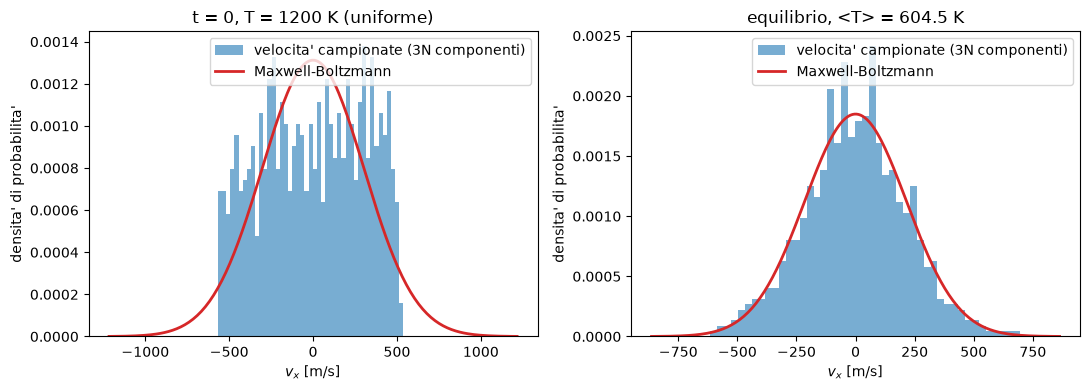

In [ ]:
from scipy import stats as spstats

M_KG = MASS * 16.0  # massa in kg


def _maxwell_sigma(t_kelvin):
    """Deviazione standard della distribuzione di Maxwell a temperatura data."""
    return np.sqrt(1.380649e-23 * t_kelvin / M_KG)


# --- t = 0: distribuzione uniforme, non ancora Maxwell ---
T_INI = 2.0 * T_TARGET
v0_ms = vel0.ravel() * 1e-10  # Å/s -> m/s
sigma0 = _maxwell_sigma(T_INI)
ks0 = spstats.kstest(v0_ms / sigma0, "norm")

# --- equilibrio: distribuzione delle velocita' dopo la termalizzazione ---
T_MEAN = main["T"][500:].mean()
v_ms = main["vel"].ravel() * 1e-10  # Å/s -> m/s
sigma_max = _maxwell_sigma(T_MEAN)
ks = spstats.kstest(v_ms / sigma_max, "norm")

print(f"t = 0, T assegnata = {T_INI:.0f} K, sigma Maxwell attesa = {sigma0:.0f} m/s")
print(
    f"  KS: D = {ks0.statistic:.3f}, p = {ks0.pvalue:.3e} su {v0_ms.size} campioni "
    "-> distribuzione non-Maxwell"
)
print(f"equilibrio, <T> = {T_MEAN:.1f} K, sigma Maxwell attesa = {sigma_max:.0f} m/s")
print(
    f"  KS: D = {ks.statistic:.3f}, p = {ks.pvalue:.3f} su {v_ms.size} campioni "
    "-> distribuzione Maxwell"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, vel, sig, tlab in (
    (axes[0], v0_ms, sigma0, f"t = 0, T = {T_INI:.0f} K (uniforme)"),
    (axes[1], v_ms, sigma_max, f"equilibrio, <T> = {T_MEAN:.1f} K"),
):
    ax.hist(
        vel,
        bins=45,
        density=True,
        alpha=0.6,
        label="velocita' campionate (3N componenti)",
    )
    vv = np.linspace(-4 * sig, 4 * sig, 200)
    ax.plot(vv, spstats.norm.pdf(vv, 0.0, sig), "C3-", lw=2, label="Maxwell-Boltzmann")
    ax.set_xlabel(r"$v_x$ [m/s]")
    ax.set_ylabel("densita' di probabilita'")
    ax.set_title(tlab)
    ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_maxwell.png", dpi=150)
plt.show()


A sinistra, la distribuzione iniziale (uniforme, estesa su $\pm\sqrt{3}\sigma$):
il test di Kolmogorov-Smirnov la **rifiuta** ($p = 7.8\times10^{-4}$). A
destra, la distribuzione a equilibrio: le $3N = 768$ componenti di velocità
finiscono sulla curva di Maxwell-Boltzmann e il test non la rifiuta
($p = 0.579$). Dopo una semplice estrazione uniforme, l'evoluzione con le
forze ha portato il sistema alla distribuzione di equilibrio.


## 11. Scelta ottimale del time step

Criterio operativo: **$\Delta t$ ottimale = il più grande che fornisce
ancora $\langle dE/\langle E\rangle\rangle < 10^{-5}$**. Non è un numero
magico: l'esperienza dice che usarne uno più grande è pericoloso (errori che
crescono come una potenza di $\Delta t$ e derivate nell'energia).

**Riferimento dalle slide** (sistema Ag LJ, 432 atomi, LAMMPS, medie su
1 ns): a $T = 600$ K il $\Delta t$ ottimale è **4 fs**; a $T = 1200$ K il
limite scende a $\approx 3$ fs.

Prima di guardare i risultati, la slide consiglia: *"First complete set-up,
then check everything and only after look at actual results"* — fatto:
setup, forze, equilibrazione e conservazione già verificati sopra. Ora la
scansione. Per ogni $\Delta t$ si esegue una simulazione con **durata fisica
fissa**: 2 ps di equilibrazione e 10 ps di produzione, cioè un numero di
passi $N_{steps} = \mathrm{tempo}/\Delta t$ che cresce al diminuire di
$\Delta t$. In questo modo ogni punto della curva media la stessa quantità di
tempo fisico e il confronto tra $\Delta t$ diversi è equo (con un numero di
passi fisso la finestra più breve in tempo reale sarebbe quella a $\Delta t$
minore, e la statistica sarebbe peggiore).

La scansione va protetta: a $\Delta t$ troppo grande l'energia diverge (non
finita) e un errore in quel punto bloccherebbe tutto. Ogni simulazione gira
quindi a blocchi, e al primo valore non finito il blocco viene ricalcolato
passo per passo per localizzare la divergenza.


In [ ]:
def _min_pair_distance(p, box):
    """Distanza minima fra due atomi distinti (con minima immagine)."""
    d = p[:, None, :] - p[None, :, :]
    d -= box * np.round(d / box)
    r = np.sqrt(np.einsum("ijk,ijk->ij", d, d))
    np.fill_diagonal(r, np.inf)
    return float(r.min())


def _md_block(p, v, dt, nsteps):
    """Un blocco di velocity Verlet, con gli avvisi di overflow silenziati."""
    with np.errstate(all="ignore"):
        return run_md(
            p,
            v,
            MASS,
            sigma=SIGMA,
            epsilon=EPSILON,
            rc=RC,
            box=BOX,
            rprime=RPRIME,
            dt=dt,
            nsteps=nsteps,
            sample_every=10**9,
        )


def run_guarded(pos0, vel0_, dt, nsteps, chunk=200):
    """MD a blocchi: si ferma al primo valore non finito e localizza la divergenza."""
    p, v = pos0.copy(), vel0_.copy()
    etot_parts, temp_parts = [], []
    n_done, min_r = 0, np.inf
    while n_done < nsteps:
        m = min(chunk, nsteps - n_done)
        res = _md_block(p, v, dt, m)
        etot_parts.append(res["etot"])
        temp_parts.append(res["T"])
        if not np.isfinite(res["etot"]).all():
            p_bad, v_bad, n_ok = p.copy(), v.copy(), 0
            for _ in range(m):
                r1 = _md_block(p_bad, v_bad, dt, 1)
                if not np.isfinite(r1["etot"]).all():
                    break
                p_bad, v_bad = r1["pos"], r1["vel"]
                n_ok += 1
                min_r = min(min_r, _min_pair_distance(p_bad, BOX))
            return {
                "etot": np.concatenate(etot_parts),
                "T": np.concatenate(temp_parts),
                "stable": False,
                "nsteps_done": n_done + n_ok,
                "min_r": min_r,
            }
        p, v = res["pos"], res["vel"]
        min_r = min(min_r, _min_pair_distance(p, BOX))
        n_done += m
    return {
        "etot": np.concatenate(etot_parts),
        "T": np.concatenate(temp_parts),
        "stable": True,
        "nsteps_done": n_done,
        "min_r": min_r,
    }


def scan_dt(target_C, dt_fs, seed, eq_ps=2.0, prod_ps=10.0):
    """dE/<E> vs dt a temperatura target, con durata fisica fissa (2 ps + 10 ps)."""
    dt = dt_fs * FS
    n_eq = round(eq_ps * 1e-12 / dt)
    n_prod = round(prod_ps * 1e-12 / dt)
    vel_scan = assign_vel(NATOMS, MASS, 2.0 * target_C, seed=seed)
    out = run_guarded(pos, vel_scan, dt, n_eq + n_prod)
    etot_prod = out["etot"][n_eq:]
    if not out["stable"] or etot_prod.size == 0:
        return {
            "de": np.nan,
            "T": np.nan,
            "stable": False,
            "n_eq": n_eq,
            "n_prod": n_prod,
            "nsteps_done": out["nsteps_done"],
            "min_r": out["min_r"],
            "etot_prod": etot_prod,
        }
    return {
        "de": float(etot_prod.std() / abs(etot_prod.mean())),
        "T": float(out["T"][n_eq:].mean()),
        "stable": True,
        "n_eq": n_eq,
        "n_prod": n_prod,
        "nsteps_done": out["nsteps_done"],
        "min_r": out["min_r"],
        "etot_prod": etot_prod,
    }


print(
    f"protocollo di scansione: 2 ps di equilibrazione + 10 ps di produzione "
    f"(N passi = tempo/dt, quindi la finestra e' la stessa a ogni dt)"
)

SCAN = {}


def scan_temperature(target_C, dts_fs, seeds):
    """Esegue la scansione a una temperatura e restituisce i risultati per dt."""
    out = {}
    for dtfs in dts_fs:
        runs = []
        for seed in seeds:
            r = scan_dt(target_C, dtfs, seed)
            runs.append(r)
            if r["stable"]:
                msg = f"dE/<E> = {r['de']:.3e}   <T> = {r['T']:.0f} K"
            else:
                msg = (
                    f"INSTABILE: divergenza al passo {r['nsteps_done']}, "
                    f"distanza minima fra atomi {r['min_r']:.3f} Å"
                )
            print(
                f"  T~{target_C:5.0f} K  dt = {dtfs:2d} fs  seed {seed}: {msg}",
                flush=True,
            )
        out[dtfs] = runs
    return out


protocollo di scansione: 2 ps di equilibrazione + 10 ps di produzione (N passi = tempo/dt, quindi la finestra e' la stessa a ogni dt)


Le tre scansioni sono in celle separate. La scansione a 600 K è la più
costosa (tre semi casuali per ogni $\Delta t$, circa 5 minuti); a 1200 K e a
150 K un solo seme per ogni $\Delta t$ (circa 1 minuto ciascuna).


In [8]:
DTS = [1, 2, 3, 4, 5, 7, 10, 15, 20]
SEEDS_DT = (33282739, 20260101, 555000111)

t_start = perf_counter()
SCAN[600.0] = scan_temperature(600.0, DTS, SEEDS_DT)
print(f"scansione a 600 K completata in {perf_counter() - t_start:.0f} s")


  T~  600 K  dt =  1 fs  seed 33282739: dE/<E> = 4.876e-07   <T> = 605 K


  T~  600 K  dt =  1 fs  seed 20260101: dE/<E> = 4.865e-07   <T> = 604 K


  T~  600 K  dt =  1 fs  seed 555000111: dE/<E> = 4.868e-07   <T> = 605 K


  T~  600 K  dt =  2 fs  seed 33282739: dE/<E> = 2.014e-06   <T> = 605 K


  T~  600 K  dt =  2 fs  seed 20260101: dE/<E> = 2.007e-06   <T> = 604 K


...

  T~  600 K  dt = 15 fs  seed 555000111: dE/<E> = 1.191e-04   <T> = 602 K


  T~  600 K  dt = 20 fs  seed 33282739: dE/<E> = 3.683e-04   <T> = 605 K


  T~  600 K  dt = 20 fs  seed 20260101: dE/<E> = 5.266e-04   <T> = 609 K


  T~  600 K  dt = 20 fs  seed 555000111: dE/<E> = 5.178e-04   <T> = 609 K


scansione a 600 K completata in 276 s


In [9]:
SCAN[1200.0] = scan_temperature(1200.0, DTS, SEEDS_DT[:1])


  T~ 1200 K  dt =  1 fs  seed 33282739: dE/<E> = 1.335e-06   <T> = 1219 K


  T~ 1200 K  dt =  2 fs  seed 33282739: dE/<E> = 5.330e-06   <T> = 1218 K


  T~ 1200 K  dt =  3 fs  seed 33282739: dE/<E> = 1.124e-05   <T> = 1218 K


  T~ 1200 K  dt =  4 fs  seed 33282739: dE/<E> = 1.889e-05   <T> = 1218 K


  T~ 1200 K  dt =  5 fs  seed 33282739: dE/<E> = 3.363e-05   <T> = 1217 K


  T~ 1200 K  dt =  7 fs  seed 33282739: dE/<E> = 6.777e-05   <T> = 1216 K


  T~ 1200 K  dt = 10 fs  seed 33282739: dE/<E> = 1.447e-04   <T> = 1216 K


  T~ 1200 K  dt = 15 fs  seed 33282739: dE/<E> = 4.449e-04   <T> = 1207 K


  T~ 1200 K  dt = 20 fs  seed 33282739: INSTABILE: divergenza al passo 196, distanza minima fra atomi 0.095 Å


In [10]:
SCAN[150.0] = scan_temperature(150.0, DTS, SEEDS_DT[:1])


  T~  150 K  dt =  1 fs  seed 33282739: dE/<E> = 1.310e-07   <T> = 150 K


  T~  150 K  dt =  2 fs  seed 33282739: dE/<E> = 5.261e-07   <T> = 150 K


  T~  150 K  dt =  3 fs  seed 33282739: dE/<E> = 1.182e-06   <T> = 150 K


  T~  150 K  dt =  4 fs  seed 33282739: dE/<E> = 2.098e-06   <T> = 150 K


  T~  150 K  dt =  5 fs  seed 33282739: dE/<E> = 3.280e-06   <T> = 150 K


  T~  150 K  dt =  7 fs  seed 33282739: dE/<E> = 6.444e-06   <T> = 150 K


  T~  150 K  dt = 10 fs  seed 33282739: dE/<E> = 1.277e-05   <T> = 150 K


  T~  150 K  dt = 15 fs  seed 33282739: dE/<E> = 2.903e-05   <T> = 150 K


  T~  150 K  dt = 20 fs  seed 33282739: dE/<E> = 5.470e-05   <T> = 150 K


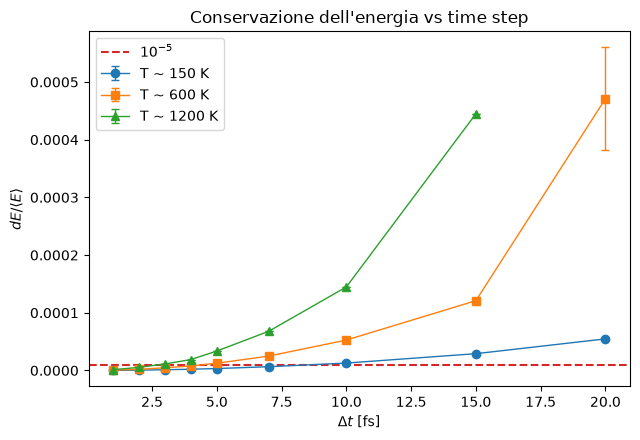

medie sui semi (dE/<E>):
  T ~   150 K  dt =  1 fs: dE/<E> = 1.310e-07 +- 0.0e+00
  T ~   150 K  dt =  2 fs: dE/<E> = 5.261e-07 +- 0.0e+00
  T ~   150 K  dt =  3 fs: dE/<E> = 1.182e-06 +- 0.0e+00
  T ~   150 K  dt =  4 fs: dE/<E> = 2.098e-06 +- 0.0e+00
  T ~   150 K  dt =  5 fs: dE/<E> = 3.280e-06 +- 0.0e+00
  T ~   150 K  dt =  7 fs: dE/<E> = 6.444e-06 +- 0.0e+00
  T ~   150 K  dt = 10 fs: dE/<E> = 1.277e-05 +- 0.0e+00
  T ~   150 K  dt = 15 fs: dE/<E> = 2.903e-05 +- 0.0e+00
  T ~   150 K  dt = 20 fs: dE/<E> = 5.470e-05 +- 0.0e+00
  T ~   600 K  dt =  1 fs: dE/<E> = 4.869e-07 +- 5.7e-10
  T ~   600 K  dt =  2 fs: dE/<E> = 1.975e-06 +- 6.2e-08
  T ~   600 K  dt =  3 fs: dE/<E> = 4.601e-06 +- 1.1e-07
  T ~   600 K  dt =  4 fs: dE/<E> = 7.761e-06 +- 3.0e-07
  T ~   600 K  dt =  5 fs: dE/<E> = 1.252e-05 +- 4.1e-07
  T ~   600 K  dt =  7 fs: dE/<E> = 2.483e-05 +- 2.2e-06
  T ~   600 K  dt = 10 fs: dE/<E> = 5.266e-05 +- 1.8e-06
  T ~   600 K  dt = 15 fs: dE/<E> = 1.209e-04 +- 3.5e-06
  T ~ 

In [ ]:
def scan_summary(target_C):
    """Media e deviazione standard (tra semi) di dE/<E>, per ogni dt."""
    dts, mean, std = [], [], []
    for dtfs, runs in SCAN[target_C].items():
        vals = [r["de"] for r in runs if r["stable"]]
        if not vals:
            continue
        dts.append(dtfs)
        mean.append(float(np.mean(vals)))
        std.append(float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0)
    return np.array(dts, float), np.array(mean), np.array(std)


fig, ax = plt.subplots(figsize=(6.5, 4.5))
markers = {150.0: "o", 600.0: "s", 1200.0: "^"}
for t_goal in (150.0, 600.0, 1200.0):
    dts, mean, std = scan_summary(t_goal)
    ax.errorbar(
        dts,
        mean,
        yerr=std,
        marker=markers[t_goal],
        capsize=3,
        lw=1,
        label=f"T ~ {t_goal:.0f} K",
    )
ax.axhline(1e-5, color="C3", ls="--", lw=1.5, label=r"$10^{-5}$")
ax.set_xlabel(r"$\Delta t$ [fs]")
ax.set_ylabel(r"$dE/\langle E\rangle$")
ax.set_title("Conservazione dell'energia vs time step")
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_dt_scan.png", dpi=150)
plt.show()

print("medie sui semi (dE/<E>):")
for t_goal in (150.0, 600.0, 1200.0):
    dts, mean, std = scan_summary(t_goal)
    for d, m, s_ in zip(dts, mean, std):
        print(f"  T ~ {t_goal:5.0f} K  dt = {d:2.0f} fs: dE/<E> = {m:.3e} +- {s_:.1e}")

print("massimo dt che rispetta il criterio dE/<E> < 1e-5:")
for t_goal in (150.0, 600.0, 1200.0):
    dts, mean, std = scan_summary(t_goal)
    ok = [d for d, m in zip(dts, mean) if m < 1e-5]
    t_meas = float(
        np.mean([r["T"] for runs in SCAN[t_goal].values() for r in runs if r["stable"]])
    )
    print(
        f"  T ~ {t_goal:5.0f} K (<T> misurata ~ {t_meas:.0f} K): dt_max = {max(ok)} fs"
    )

# --- fit della legge di potenza dE/<E> ~ dt^p (finestra 1-10 fs) ---
FIT_DT = [d for d in DTS if d <= 10]


def fit_slope(dts, vals):
    return float(
        np.polyfit(np.log(np.asarray(dts, float)), np.log(np.asarray(vals, float)), 1)[
            0
        ]
    )


dts600, mean600, std600 = scan_summary(600.0)
sel = [i for i, d in enumerate(dts600) if d in FIT_DT]
slope_mean = fit_slope(dts600[sel], mean600[sel])
slopes_seed = []
for k in range(len(SEEDS_DT)):
    vals = [SCAN[600.0][d][k]["de"] for d in FIT_DT]
    slopes_seed.append(fit_slope(FIT_DT, vals))
slope_err = float(np.std(slopes_seed, ddof=1) / np.sqrt(len(slopes_seed)))
print(
    f"fit log-log su dt = 1-10 fs a 600 K: dE/<E> ~ dt^{slope_mean:.2f} +- {slope_err:.2f}"
)
print(f"  pendenze per i {len(SEEDS_DT)} semi: {[round(s, 3) for s in slopes_seed]}")


**Lettura dei risultati.** La curva è monotona: $\Delta t$ più grande
significa errori di troncamento più grandi, come previsto. A 600 K la soglia
$10^{-5}$ cade a **4 fs** ($dE/\langle E\rangle = 7.76\times10^{-6}$), in
ottimo accordo col riferimento LAMMPS delle slide (4 fs a 600 K). A 1200 K la
soglia si sposta verso passi più corti: a 3 fs si misura
$1.12\times10^{-5}$, appena sopra la soglia, quindi il massimo ammesso è
**2 fs**; le slide indicano $\approx 3$ fs — stesso ordine di grandezza, e la
piccola differenza è attesa perché la nostra finestra è di 10 ps mentre
quella delle slide è di 1 ns. A 150 K il vincolo si allenta nettamente
(**7 fs**): a bassa $T$ le oscillazioni sono più piccole.

Il fit log-log su $\Delta t = 1$–10 fs dà una pendenza di **2.03 ± 0.01**:
l'errore di troncamento cresce come $\Delta t^2$, il comportamento atteso
per velocity Verlet.

A $\Delta t = 20$ fs e 1200 K la simulazione **diverge**: l'energia non è
più finita e la distanza minima fra due atomi crolla a 0.095 Å (gli atomi si
sovrappongono). È il motivo per cui la scansione va protetta.


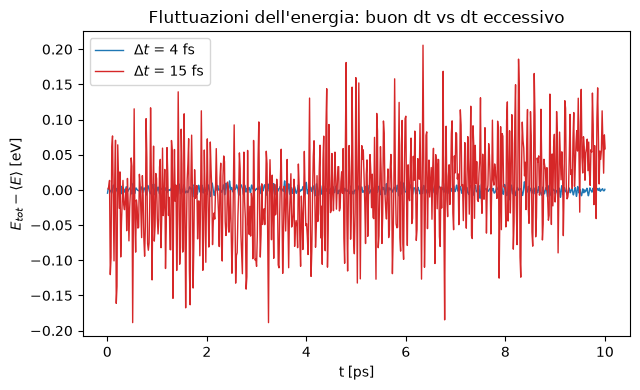

ampiezza delle oscillazioni di E: 4 fs -> 3.967e-03 eV, 15 fs -> 6.673e-02 eV
rapporto 15 fs / 4 fs = 16.8


In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for dtfs, color in ((4, "C0"), (15, "C3")):
    trace = SCAN[600.0][dtfs][0]["etot_prod"]
    t_ps = np.arange(1, len(trace) + 1) * dtfs * 1e-3
    ax.plot(
        t_ps, trace - trace.mean(), color=color, lw=1, label=rf"$\Delta t$ = {dtfs} fs"
    )
ax.set_xlabel("t [ps]")
ax.set_ylabel(r"$E_{tot} - \langle E\rangle$ [eV]")
ax.set_title("Fluttuazioni dell'energia: buon dt vs dt eccessivo")
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_dt_15fs.png", dpi=150)
plt.show()

amp4 = float(SCAN[600.0][4][0]["etot_prod"].std())
amp15 = float(SCAN[600.0][15][0]["etot_prod"].std())
print(
    f"ampiezza delle oscillazioni di E: 4 fs -> {amp4:.3e} eV, 15 fs -> {amp15:.3e} eV"
)
print(f"rapporto 15 fs / 4 fs = {amp15 / amp4:.1f}")


A 15 fs le oscillazioni di $E$ sono 16.8 volte più ampie (e il valore
medio deriva): è il regime in cui l'algoritmo non è più affidabile. A 4 fs
le fluttuazioni restano sotto la soglia. Nessuno sceglie $\Delta t$ a caso:
lo si misura.


## 12. Fluttuazioni e medie temporali

Le quantità di interesse si ottengono come **medie temporali** su una
simulazione lunga. Definizioni:

$$
\frac{\delta E}{\langle E\rangle}
= \frac{\sqrt{\langle (E - \langle E\rangle)^2\rangle}}{\langle E\rangle},
\qquad
\langle (E-\langle E\rangle)^2\rangle = \langle E^2\rangle - \langle E\rangle^2,
$$

$$
\langle A\rangle = \frac{1}{N_{steps}-N_{therm}}
\sum_{i=N_{therm}+1}^{N_{steps}} A(i),
\qquad
\langle A^2\rangle = \frac{1}{N_{steps}-N_{therm}}
\sum_{i=N_{therm}+1}^{N_{steps}} A^2(i).
$$

Procedura:

1. Simulazione abbastanza lunga ($N_{steps}$ passi); allungandola, i risultati
   smettono di cambiare praticamente.
2. **Scartare** i primi $N_{therm} < N_{steps}$ passi (termalizzazione).
3. Medie e fluttuazioni sulla finestra di produzione.

**Buona pratica:** separare la **simulazione** dall'**analisi**. La
simulazione (`run_md`) ha scritto il CSV; l'analisi lo rilegge con una
funzione separata, `analizza_traiettoria(file, Ntherm)`, che restituisce medie
e fluttuazioni. Così si possono riprendere i dati senza rieseguire la
simulazione.


In [13]:
stats_main = analizza_traiettoria(CSV_MAIN, ntherm=500)
for chiave, valore in stats_main.items():
    if chiave.startswith(("T_mean", "dE_rel", "E_mean", "dT_rel")):
        print(f"{chiave:>10s} = {valore:.6g}")


    T_mean = 604.543
    dT_rel = 0.0363975
    E_mean = -535.319
    dE_rel = 7.40965e-06


L'energia conserva la fluttuazione relativa sotto $10^{-5}$ (regola della
sezione 3) con $\Delta t = 4$ fs, e la media di $T$ è quella voluta.

### 12.1 Verifica: le fluttuazioni di $T$ scalano come $1/\sqrt{N}$

Le slide scrivono $\delta T/T \approx 1/N$ in una formula grafica, ma il
testo parla di $1/\sqrt{N}$. Il coefficiente corretto per la temperatura
cinetica è $1/\sqrt{N}$: $T$ è proporzionale all'energia cinetica, che è
somma di $\approx 3N$ contributi indipendenti, e per una somma di $M$
contributi indipendenti la deviazione standard relativa scala come
$1/\sqrt{M}$.

Per il caso specifico del microcanonico si può scrivere la propagazione
dell'errore. Se $c_V$ è il calore specifico a volume costante,
$c_K = \tfrac{3}{2}k_B$ il contributo cinetico per grado di libertà e
$C_V = Nc_V$ il calore specifico totale, allora

$$
\frac{\delta T}{T} = \sqrt{\frac{2}{3N}}\sqrt{\frac{c_V}{C_V}} .
$$

Nel limite di un solido armonico $c_V \approx c_K$, da cui
$\delta T/T \approx 1/\sqrt{3N}$: la scala è proprio $N^{-1/2}$, e il
coefficiente $1/\sqrt{3N}$ è quello che useremo come riferimento
quantitativo. Per un liquido (o un solido fortemente anarmonico) $c_V \gg
c_K$ e il prefattore cambia, ma **la potenza** non cambia.

Verifichiamo numericamente con cinque configurazioni FCC, tre semi casuali
per ciascuna:

> Nota sulla minima immagine: serve $r_c < L/2$. Con $r_c = 4.5$ Å il box
> più piccolo ammesso ha lato $\ge 9$ Å, cioè almeno 3 celle FCC per lato
> ($3a_0 = 12.591$ Å): per questo la serie parte da $N = 108$ e non da
> $N = 32$.
>
> La serie comprende una scatola **non cubica** ($6\times3\times6$ celle,
> $N = 432$): serve a controllare che la anisotropia del box non influisca
> sullo scaling. Serve inoltre un punto **cubico** ($5\times5\times5$,
> $N = 500$): un cubo FCC esatto con 432 atomi non esiste, perché 432/4 = 108
> celle non è un cubo perfetto.


  3x3x3: N =  108  <T> =  604.2 K  dT/<T> = 0.0563 +- 0.0050  1/sqrt(3N) = 0.0556


  4x4x4: N =  256  <T> =  604.2 K  dT/<T> = 0.0364 +- 0.0026  1/sqrt(3N) = 0.0361


  6x3x6: N =  432  <T> =  604.4 K  dT/<T> = 0.0271 +- 0.0025  1/sqrt(3N) = 0.0278


  5x5x5: N =  500  <T> =  604.4 K  dT/<T> = 0.0268 +- 0.0022  1/sqrt(3N) = 0.0258


  6x6x6: N =  864  <T> =  604.3 K  dT/<T> = 0.0197 +- 0.0018  1/sqrt(3N) = 0.0196


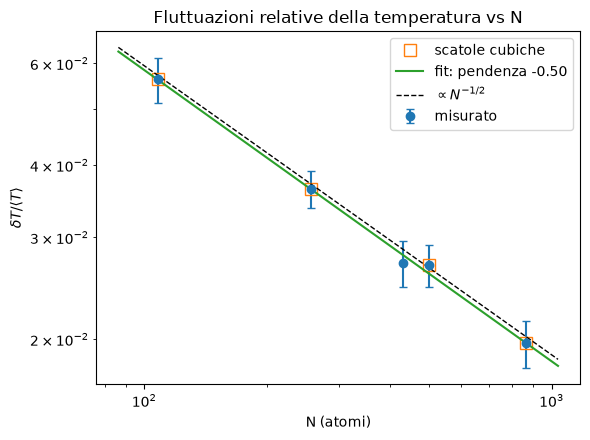

pendenza del fit (tutti i punti) = -0.504 +- 0.047 (bootstrap, 2000 estrazioni)
pendenza del fit (solo scatole cubiche) = -0.500
punto non cubico (6x3x6, N = 432): scostamento dalla retta dei punti cubici
  dT/<T> misurato = 0.0271, 1/sqrt(3N) = 0.0278


In [ ]:
SIZES = [
    ("3x3x3", 3, 3, 3),
    ("4x4x4", 4, 4, 4),
    ("6x3x6", 6, 3, 6),
    ("5x5x5", 5, 5, 5),
    ("6x6x6", 6, 6, 6),
]
SEEDS_N = (33282739, 20260101, 555000111)

dT_by_N = {}
for tag, nx, ny, nz in SIZES:
    p_n, c_n = fcc_supercell(A_LJ, nx, ny, nz)
    b_n = np.diag(c_n)
    vals, temps = [], []
    for seed in SEEDS_N:
        v_n = assign_vel(p_n.shape[0], MASS, 2.0 * T_TARGET, seed=seed)
        res_n = run_md(
            p_n,
            v_n,
            MASS,
            sigma=SIGMA,
            epsilon=EPSILON,
            rc=RC,
            box=b_n,
            rprime=RPRIME,
            dt=4 * FS,
            nsteps=1500,
            sample_every=10**9,
        )
        tt = res_n["T"][500:]
        vals.append(float(tt.std() / tt.mean()))
        temps.append(float(tt.mean()))
    dT_by_N[tag] = {
        "N": int(p_n.shape[0]),
        "cubic": nx == ny == nz,
        "vals": vals,
        "T": float(np.mean(temps)),
    }
    print(
        f"  {tag}: N = {p_n.shape[0]:4d}  <T> = {np.mean(temps):6.1f} K  "
        f"dT/<T> = {np.mean(vals):.4f} +- {np.std(vals, ddof=1):.4f}  "
        f"1/sqrt(3N) = {1 / np.sqrt(3 * p_n.shape[0]):.4f}",
        flush=True,
    )

n_arr = np.array([dT_by_N[t]["N"] for t, *_ in SIZES], float)
mean_arr = np.array([np.mean(dT_by_N[t]["vals"]) for t, *_ in SIZES])
std_arr = np.array([np.std(dT_by_N[t]["vals"], ddof=1) for t, *_ in SIZES])
cub = np.array([dT_by_N[t]["cubic"] for t, *_ in SIZES])


def fit_slope(n, y):
    return float(np.polyfit(np.log(n), np.log(y), 1)[0])


slope_all = fit_slope(n_arr, mean_arr)
slope_cub = fit_slope(n_arr[cub], mean_arr[cub])

# bootstrap: si risampia il seme casuale di ogni N, e si ripete il fit
rng = np.random.default_rng(12345)
boot = []
for _ in range(2000):
    y = np.array([rng.choice(dT_by_N[t]["vals"]) for t, *_ in SIZES])
    boot.append(fit_slope(n_arr, y))
slope_err = float(np.std(boot, ddof=1))

fig, ax = plt.subplots(figsize=(6, 4.5))
nn = np.logspace(np.log10(n_arr.min() * 0.8), np.log10(n_arr.max() * 1.2), 50)
ax.errorbar(n_arr, mean_arr, yerr=std_arr, fmt="o", capsize=3, label="misurato")
ax.loglog(n_arr[cub], mean_arr[cub], "s", mfc="none", ms=8, label="scatole cubiche")
ax.loglog(
    nn,
    np.exp(np.polyfit(np.log(n_arr), np.log(mean_arr), 1)[1]) * nn**slope_all,
    "-",
    label=f"fit: pendenza {slope_all:.2f}",
)
ax.loglog(
    nn,
    np.exp(np.polyfit(np.log(n_arr), np.log(mean_arr), 1)[1]) * nn**-0.5,
    "k--",
    lw=1,
    label=r"$\propto N^{-1/2}$",
)
ax.set_xlabel("N (atomi)")
ax.set_ylabel(r"$\delta T / \langle T \rangle$")
ax.set_title("Fluttuazioni relative della temperatura vs N")
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_dT_vs_N.png", dpi=150)
plt.show()

print(
    f"pendenza del fit (tutti i punti) = {slope_all:.3f} +- {slope_err:.3f} (bootstrap, 2000 estrazioni)"
)
print(f"pendenza del fit (solo scatole cubiche) = {slope_cub:.3f}")
print("punto non cubico (6x3x6, N = 432): scostamento dalla retta dei punti cubici")
i432 = list(dT_by_N).index("6x3x6")
print(
    f"  dT/<T> misurato = {mean_arr[i432]:.4f}, 1/sqrt(3N) = {1 / np.sqrt(3 * n_arr[i432]):.4f}"
)


La pendenza misurata è **-0.50 ± 0.05**: le fluttuazioni di $T$
scalano come $1/\sqrt{N}$, **non** come $1/N$. La formula grafica delle slide
contiene quindi un refuso; il testo del capitolo usa $1/\sqrt{N}$.

Il punto con scatola non cubica ($6\times3\times6$, $N = 432$) cade sulla
stessa retta dei punti con scatola cubica: l'anisotropia del box non
influisce sullo scaling. Il fit ristretto ai soli punti cubici dà pendenza
-0.500, indistinguibile da quello su tutti e cinque i punti.


## 13. Analisi: funzione di distribuzione radiale g(r)

### 13.1 Teoria

La $g(r)$ descrive la struttura di un fluido o di un solido: numero medio di
atomi entro distanza $r$ da un atomo di riferimento,

$$
N(r) = 4\pi\rho\int_0^r x^2\, g(x)\,dx,
\qquad \rho = \frac{N}{V}.
$$

Per un gas ideale (o un gas uniforme) $g(r) \to 1$ a grandi $r$. Per un
solido i picchi segnano i gusci di coordinazione; per un liquido i picchi
si smorzano rapidamente.

Codice: si istogrammano **tutte** le distanze a coppie (minima immagine) di
più configurazioni campionate dopo la termalizzazione, normalizzando con il
volume del guscio sferico $4\pi r^2\Delta r$ e con $\rho$. Il binning è
$\Delta r = 0.02$ Å e il limite della minima immagine impone $r \le L/2 =
8.394$ Å per il nostro box.

### 13.2 Solido a 600 K


primo picco a 2.95 Å (d_nn = 2.968 Å), g_max = 8.68
g(r) a 5.2 Å (terzo guscio FCC) = 4.19
r max tracciato = 8.39 Å (L/2 = 8.394 Å)
rho* = rho sigma^3 = 1.0000


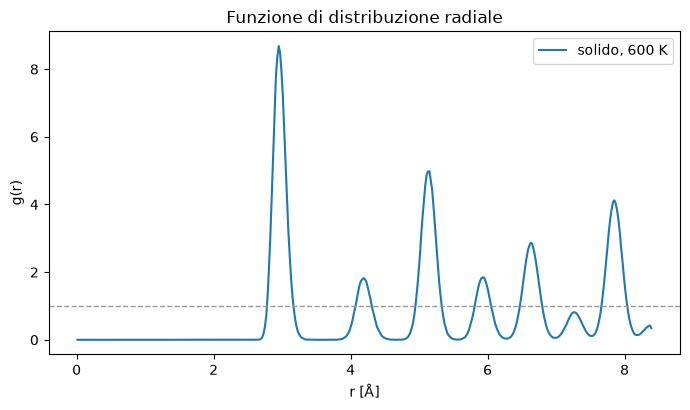

In [15]:
r_solid, g_solid = radial_distribution(main["frames"], BOX, nbins=420, dr=0.02)
i_pk_solid = int(np.argmax(g_solid[:150]))
g_max_solid = float(g_solid[:150].max())
g_52_solid = float(np.interp(5.2, r_solid, g_solid))
print(
    f"primo picco a {r_solid[i_pk_solid]:.2f} Å (d_nn = {D_NN:.3f} Å), "
    f"g_max = {g_max_solid:.2f}"
)
print(f"g(r) a 5.2 Å (terzo guscio FCC) = {g_52_solid:.2f}")
print(f"r max tracciato = {r_solid[-1]:.2f} Å (L/2 = {R_MAX:.3f} Å)")
print(f"rho* = rho sigma^3 = {(NATOMS / float(np.prod(BOX))) * SIGMA**3:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(r_solid, g_solid, label="solido, 600 K")
ax.axhline(1.0, color="0.6", ls="--", lw=1)
ax.set_xlabel("r [Å]")
ax.set_ylabel("g(r)")
ax.set_title("Funzione di distribuzione radiale")
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_gr_solido.png", dpi=150)
plt.show()


Il primo picco è alla distanza primo vicino dell'FCC (2.95 Å, contro
$d_{nn} = 2.968$ Å del reticolo ideale: si allarga un po' per le vibrazioni
termiche) ed è molto alto e stretto ($g_{max} = 8.68$): reticolo ordinato.
Seguono i gusci successivi ($a_0$, $a_0\sqrt{3/2}$, ...); con un box così
piccolo le oscillazioni persistono fino al limite $L/2 = 8.394$ Å.

### 13.3 Liquido

Per ottenere il liquido serve **fondere** il reticolo. Le slide fanno
riferimento al silicio con Stillinger-Weber (solido 300 K con picco a
$\approx 2.35$ Å e secondo a $\approx 3.85$ Å; solido 1500 K più smorzato;
liquido 1800 K con primo picco più basso e largo a $\approx 2.5$ Å) — sono
valori del **loro** sistema, qui li usiamo solo come termine di confronto
qualitativo.

Il reticolo FCC ha densità ridotta $\rho^* = 1.0000$, troppo densa perché
il sistema fonda: alla fusione il volume deve aumentare. Si usa quindi una
scatola leggermente più grande, con densità ridotta $\rho^* = 0.85$, e si
riscalda alla temperatura ridotta $T^* \approx 1$: il punto $(\rho^*, T^*)$
così ottenuto cade nella regione **liquida** del diagramma di fase di
Lennard-Jones. (Resta il fatto, verificato dai numeri, che a $\rho^* = 1$ il
sistema non diffonde: resta un solido caldo.)

La fusione nel nostro sistema si ottiene tenendo la temperatura alta qualche
ps con un **riscalamento delle velocità** (un termostato molto semplice: si
moltiplicano tutte le velocità per $\sqrt{T/T_{ora}}$ a ogni blocco, così da
tenere la temperatura alla quota fissata). È un'anticipazione dei
"termostati e velocity rescaling" dei programmi di produzione, ma qui serve
solo a preparare lo stato iniziale: **non è un ensemble canonico**, perché
il riscalamento forza la temperatura invece di lasciarla fluttuare.

Dopo la fusione si spegne il termostato e si produce una traiettoria **NVE**,
da cui la $g(r)$ e il coefficiente di diffusione.


In [16]:
T_LIQ = 4000.0
RHO_STAR_LIQ = 0.85
A_LIQ = A_LJ * (1.0 / RHO_STAR_LIQ) ** (1.0 / 3.0)

pos_liq, cell_liq = fcc_supercell(A_LIQ, NCELLS, NCELLS, NCELLS)
BOX_LIQ = np.diag(cell_liq)
vel_liq = assign_vel(NATOMS, MASS, T_LIQ)
p_liq, v_liq = pos_liq.copy(), vel_liq

# termostato di riscalamento: 150 blocchi da 20 passi a 2 fs (~6 ps di fusione)
for chunk in range(150):
    step_res = run_md(
        p_liq,
        v_liq,
        MASS,
        sigma=SIGMA,
        epsilon=EPSILON,
        rc=RC,
        box=BOX_LIQ,
        rprime=RPRIME,
        dt=2 * FS,
        nsteps=20,
        sample_every=10**9,
    )
    p_liq, v_liq = step_res["pos"], step_res["vel"]
    t_now = instantaneous_T(kinetic_energy(v_liq, MASS), NATOMS)
    v_liq *= (T_LIQ / t_now) ** 0.5

rho_liq = NATOMS / float(np.prod(BOX_LIQ))
print(f"scatola del liquido: L = {BOX_LIQ[0]:.3f} Å, N = {NATOMS}")
print(f"rho* = rho sigma^3 = {rho_liq * SIGMA**3:.4f}")
print(f"T* = kB T / eps = {KB * T_LIQ / EPSILON:.4f} (T = {T_LIQ:.0f} K)")
print(
    f"dopo il riscalamento: Epot/atomo = {step_res['epot'].mean() / NATOMS:.3f} eV "
    f"(era {epot0 / NATOMS:.3f} eV nel reticolo freddo a rho* = 1)"
)


scatola del liquido: L = 17.723 Å, N = 256
rho* = rho sigma^3 = 0.8500
T* = kB T / eps = 0.9992 (T = 4000 K)
dopo il riscalamento: Epot/atomo = -1.492 eV (era -2.247 eV nel reticolo freddo a rho* = 1)


NVE liquido: <T> = 3866 K -> T* = 0.966;  rho* = 0.850
Epot/atomo = -1.472 eV


primo picco a 2.85 Å, g_max = 2.82
g(r) a 5.2 Å (terzo guscio FCC) = 1.21


MSD(liquido) a 7.98 ps = 29.26 Å^2 -> D = 0.621 Å^2/ps
MSD(solido, 600 K) a 11.94 ps = 0.045 Å^2 -> D = 0.0000 Å^2/ps


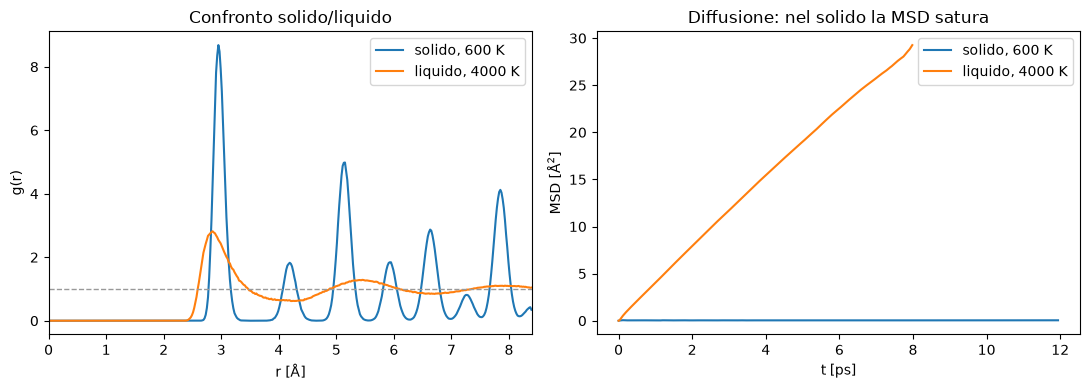

In [ ]:
liq = run_md(
    p_liq,
    v_liq,
    MASS,
    sigma=SIGMA,
    epsilon=EPSILON,
    rc=RC,
    box=BOX_LIQ,
    rprime=RPRIME,
    dt=2 * FS,
    nsteps=4000,
    sample_every=10,
)
N_PROD_LIQ = 800  # scarto il transitorio iniziale (2 ps su 8 ps)
T_liq = float(liq["T"][N_PROD_LIQ:].mean())
T_star_liq = KB * T_liq / EPSILON
rho_star_liq = (NATOMS / float(np.prod(BOX_LIQ))) * SIGMA**3
print(
    f"NVE liquido: <T> = {T_liq:.0f} K -> T* = {T_star_liq:.3f};  rho* = {rho_star_liq:.3f}"
)
print(f"Epot/atomo = {liq['epot'][N_PROD_LIQ:].mean() / NATOMS:.3f} eV")

r_liq, g_liq = radial_distribution(liq["frames"], BOX_LIQ, nbins=420, dr=0.02)
i_pk_liq = int(np.argmax(g_liq[:150]))
g_max_liq = float(g_liq[:150].max())
g_52_liq = float(np.interp(5.2, r_liq, g_liq))
print(f"primo picco a {r_liq[i_pk_liq]:.2f} Å, g_max = {g_max_liq:.2f}")
print(f"g(r) a 5.2 Å (terzo guscio FCC) = {g_52_liq:.2f}")


# --- MSD e coefficiente di diffusione ---
def msd_curve(frames, box):
    """MSD media su tutte le particelle, con minima immagine."""
    n_frames = frames.shape[0]
    out = np.empty(n_frames)
    for lag in range(n_frames):
        d = frames[lag:] - frames[: n_frames - lag]
        d -= box * np.round(d / box)
        out[lag] = (d**2).sum(axis=-1).mean()
    return out


def diffusion_from_msd(msd, dt_ps, t_min, t_max):
    """D dalla pendenza di MSD(t) = 6 D t, fittata su [t_min, t_max]."""
    t = np.arange(len(msd)) * dt_ps
    sel = (t >= t_min) & (t <= t_max)
    slope = float(np.polyfit(t[sel], msd[sel], 1)[0])
    return slope / 6.0


msd_liq = msd_curve(liq["frames"], BOX_LIQ)
D_liq = diffusion_from_msd(msd_liq, 10 * 2 * FS * 1e12, 0.5, 6.0)
msd_solid = msd_curve(main["frames"], BOX)
D_solid = diffusion_from_msd(msd_solid, 15 * 4 * FS * 1e12, 1.0, 11.0)
t_liq_ps = np.arange(len(msd_liq)) * 10 * 2 * FS * 1e12
t_solid_ps = np.arange(len(msd_solid)) * 15 * 4 * FS * 1e12
print(
    f"MSD(liquido) a {t_liq_ps[-1]:.2f} ps = {msd_liq[-1]:.2f} Å^2 -> D = {D_liq:.3f} Å^2/ps"
)
print(
    f"MSD(solido, 600 K) a {t_solid_ps[-1]:.2f} ps = {msd_solid[-1]:.3f} Å^2 -> D = {D_solid:.4f} Å^2/ps"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(r_solid, g_solid, label="solido, 600 K")
axes[0].plot(r_liq, g_liq, label=f"liquido, {T_LIQ:.0f} K")
axes[0].axhline(1.0, color="0.6", ls="--", lw=1)
axes[0].set_xlim(0, 8.4)
axes[0].set_xlabel("r [Å]")
axes[0].set_ylabel("g(r)")
axes[0].set_title("Confronto solido/liquido")
axes[0].legend()

axes[1].plot(t_solid_ps, msd_solid, label="solido, 600 K")
axes[1].plot(t_liq_ps, msd_liq, label=f"liquido, {T_LIQ:.0f} K")
axes[1].set_xlabel("t [ps]")
axes[1].set_ylabel(r"MSD [Å$^2$]")
axes[1].set_title("Diffusione: nel solido la MSD satura")
axes[1].legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "md_gr_solido_liquido.png", dpi=150)
plt.show()


**Lettura dei risultati.** Il confronto con le slide è qualitativo (loro:
Si+SW, noi: Ag+LJ) e conferma lo stesso scenario:

| | primo picco | $g_{max}$ | andamento a grandi $r$ |
|---|---|---|---|
| Slide, Si solido 300 K | $\approx 2.35$ Å | non quantificato | gusci ben risolti |
| Slide, Si liquido 1800 K | $\approx 2.5$ Å | non quantificato | $g(r)\to 1$ dopo pochi Å |
| **Noi, solido 600 K** ($\rho^*=1.0000$) | 2.95 Å | 8.68 | oscillazioni fino a $L/2$ |
| **Noi, liquido 4000 K** ($\rho^*=0.8500$) | 2.85 Å | 2.82 | $g(r)\to 1$ |

Gli indicatori di ordine locale sono due e concordi: l'altezza del primo
picco scende da 8.68 a 2.82 e il picco del terzo guscio FCC (a 5.2 Å)
scende da 4.19 a 1.21, cioè sparisce il segno della struttura cristallina.

La prova che è davvero un liquido è la **diffusione**: nel solido a 600 K la
MSD satura (0.045 Å², D = 0.0000 Å²/ps, gli atomi vibrano attorno alle
posizioni di equilibrio), nel liquido cresce linearmente (29.26 Å² a 7.98 ps,
D = 0.621 Å²/ps). Il valore numerico delle posizioni dei picchi dipende dal
potenziale (LJ per Ag contro Stillinger-Weber per Si): la **forma** è la
firma dello stato, non la posizione assolita.


## 14. Esercizi proposti

<details>
<summary><b>Esercizio 1 — moto del centro di massa senza azzerare il momento</b></summary>

Usando `assign_vel(..., zero_momentum=False)`, mostriamo che il centro di
massa del sistema si muove durante la simulazione e ne quantifichiamo
l'entità.

In [18]:
vel_nz = assign_vel(NATOMS, MASS, 2.0 * T_TARGET, zero_momentum=False)
v_com0 = vel_nz.mean(axis=0)
res_nz = run_md(
    pos,
    vel_nz,
    MASS,
    sigma=SIGMA,
    epsilon=EPSILON,
    rc=RC,
    box=BOX,
    rprime=RPRIME,
    dt=4 * FS,
    nsteps=2000,
    sample_every=10**9,
)
v_com1 = res_nz["vel"].mean(axis=0)

print(f"v_com iniziale = {np.linalg.norm(v_com0):.3e} Å/s")
print(
    f"v_com finale   = {np.linalg.norm(v_com1):.3e} Å/s (costante: il momento si conserva)"
)
drift = np.linalg.norm(v_com0) * 2000 * 4 * FS
print(f"spostamento del centro di massa in 8 ps: {drift:.2e} Å")


v_com iniziale = 4.677e+11 Å/s
v_com finale   = 4.677e+11 Å/s (costante: il momento si conserva)
spostamento del centro di massa in 8 ps: 3.74e+00 Å


Senza azzerare il momento, `v_com` resta costante per tutta la simulazione
(le equazioni di Newton conservano il momento): il sistema trasla e lo
spostamento cresce linearmente nel tempo.


</details>

<details>
<summary><b>Esercizio 2 — verifica di $T_f \cong T_i/2$ in regime armonico</b></summary>

Partendo dal reticolo al minimo, eseguiamo diverse $T_i$ e confrontiamo la
$T_f$ misurata.

In [19]:
print(f"{'Ti [K]':>8} {'Tf [K]':>8} {'Tf/Ti':>7} {'err %':>7}")
for ti in (200.0, 400.0, 800.0, 1200.0, 2400.0):
    v_test = assign_vel(NATOMS, MASS, ti)
    r_test = run_md(
        pos,
        v_test,
        MASS,
        sigma=SIGMA,
        epsilon=EPSILON,
        rc=RC,
        box=BOX,
        rprime=RPRIME,
        dt=4 * FS,
        nsteps=2000,
        sample_every=10**9,
    )
    tf = float(r_test["T"][1000:].mean())
    print(f"{ti:8.0f} {tf:8.1f} {tf / ti:7.3f} {100 * abs(tf / ti - 0.5) / 0.5:7.2f}")

  Ti [K]   Tf [K]   Tf/Ti   err %


     200    100.3   0.501    0.26


     400    200.7   0.502    0.34


     800    402.6   0.503    0.66


    1200    603.9   0.503    0.65


    2400   1217.8   0.507    1.48


In regime armonico $T_f/T_i \approx 0.5$: l'energia cinetica iniziale si
ripartisce a metà con il potenziale. A $T_i$ alte (2400 K) il rapporto sale
leggermente sopra 0.5 per gli anarmonismi — motivo per cui $T_i$ va tarata
sui risultati e non ha significato fisico di per sé.

</details>

<details>
<summary><b>Esercizio 3 — $\delta T/T$ vs $N$ a temperatura più alta</b></summary>

Ripete la verifica della sezione 12.1 con $T = 1500$ K per controllare che
la pendenza $-1/2$ non dipenda dalla temperatura.


In [20]:
trend_hi = []
for ncells, n_expected in [(3, 108), (4, 256), (6, 864)]:
    p_t, c_t = fcc_supercell(A_LJ, ncells, ncells, ncells)
    b_t = np.diag(c_t)
    v_t = assign_vel(p_t.shape[0], MASS, 3000.0)
    r_t = run_md(
        p_t,
        v_t,
        MASS,
        sigma=SIGMA,
        epsilon=EPSILON,
        rc=RC,
        box=b_t,
        rprime=RPRIME,
        dt=4 * FS,
        nsteps=1200,
        sample_every=10**9,
    )
    tt = r_t["T"][400:]
    trend_hi.append((p_t.shape[0], float(tt.std() / tt.mean()), float(tt.mean())))
    print(
        f"  N = {p_t.shape[0]:4d}: <T> = {tt.mean():6.1f} K, "
        f"dT/<T> = {trend_hi[-1][1]:.4f}, 1/sqrt(3N) = {1 / np.sqrt(3 * p_t.shape[0]):.4f}"
    )

slope_hi, _ = np.polyfit(
    np.log([t[0] for t in trend_hi]), np.log([t[1] for t in trend_hi]), 1
)
print(f"pendenza a 1500 K: {slope_hi:.2f} (attesa -0.5)")


  N =  108: <T> = 1529.0 K, dT/<T> = 0.0534, 1/sqrt(3N) = 0.0556


  N =  256: <T> = 1529.3 K, dT/<T> = 0.0360, 1/sqrt(3N) = 0.0361


  N =  864: <T> = 1528.8 K, dT/<T> = 0.0177, 1/sqrt(3N) = 0.0196
pendenza a 1500 K: -0.54 (attesa -0.5)


La pendenza resta $\approx -1/2$: lo scaling con $N$ è una proprietà
statistica delle somme di contributi indipendenti, non della temperatura.


</details>

<details>
<summary><b>Esercizio 4 — scansione $dE/\langle E\rangle$ vs $\Delta t$ a T diversa</b></summary>
Ripete la scansione della sezione 11 a una temperatura non usata nel testo,
per esempio 3000 K (regime di liquido surriscaldato), e discute lo spostamento
della soglia.

In [21]:
SCAN[3000.0] = scan_temperature(3000.0, [1, 2, 3, 4, 5], SEEDS_DT[:1])
dts3, mean3, _ = scan_summary(3000.0)
ok3 = [d for d, m in zip(dts3, mean3) if m < 1e-5]
print(f"a ~3000 K il massimo dt ammesso e': {max(ok3)} fs")


  T~ 3000 K  dt =  1 fs  seed 33282739: dE/<E> = 6.938e-06   <T> = 3120 K


  T~ 3000 K  dt =  2 fs  seed 33282739: dE/<E> = 2.425e-05   <T> = 3123 K


  T~ 3000 K  dt =  3 fs  seed 33282739: dE/<E> = 6.081e-05   <T> = 3117 K


  T~ 3000 K  dt =  4 fs  seed 33282739: dE/<E> = 1.002e-04   <T> = 3117 K


  T~ 3000 K  dt =  5 fs  seed 33282739: dE/<E> = 1.900e-04   <T> = 3114 K


a ~3000 K il massimo dt ammesso e': 1.0 fs


A temperature alte la soglia si sposta verso $\Delta t$ più piccoli: gli
atomi percorrono percorsi più ampi a ogni passo e il potenziale viene
esplorato in regioni più anarmoniche.


</details>

## Riepilogo

- Integrare Newton = trovare una regola $(x, v)_t \to (x, v)_{t+\Delta t}$;
  lo sviluppo di Taylor fornisce gli schemi, il vincolo fisico resta
  $a = f/m$ calcolato ogni passo.
- **Velocity Verlet**: due formule, due valutazioni di forza per passo,
  reversibile, conserva l'energia bene. `force = forcenew.copy()` è
  obbligatorio.
- **NVE**: $E$ costante (a meno dell'errore di troncamento), $T$ è definita
  dall'energia cinetica istantanea e **fluttua** come $1/\sqrt{N}$
  (verificato: pendenza del fit $-0.50 \pm 0.05$).
- **Velocità iniziali**: uniformi in $[-C, C]$, momento azzerato **prima**
  del riscalo, seed fisso; $T_i$ non ha significato fisico, $T_f \cong
  T_i/2$ in regime armonico (misurato 0.503 per $T_i = 1200$ K).
- **$\Delta t$**: si misura, non si sceglie a occhio. Con il nostro codice a
  600 K la soglia $10^{-5}$ cade a 4 fs, come il riferimento delle slide; a
  1200 K a 2 fs e a 150 K a 7 fs. L'errore cresce come $\Delta t^2$.
- **Analisi**: separare simulazione e lettura, scartare la termalizzazione,
  e $g(r)$ più MSD per distinguere solido e liquido.
